# Seasonal and Monthly Analysis - Ebro River Basin

This notebook performs temporal analysis of discharge patterns, repeating correlation and clustering analyses by:
- Monthly periods (using Jdate)
- Seasonal periods (Winter, Spring, Summer, Autumn)

## Objectives

1. **Step 5**: Repeat correlation analysis (Step 3) by months/seasons
2. Repeat clustering analysis (Step 4) by months/seasons
3. Identify temporal patterns in discharge behavior
4. Compare how basin groupings change across seasons

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os
import seaborn as sns

# Clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore", message="Could not infer format")

## Load Cleaned Data

In [2]:
base_path = "../../data/clean/merged_data/"

# Reconstruct the dictionary
join_dict = {}

for filename in os.listdir(base_path):
    if filename.endswith("-with-outliers.json"):
        basin_name = os.path.splitext(filename)[0]
        df = pd.read_json(os.path.join(base_path, filename), orient="records")
        join_dict[basin_name] = df

print(f"Loaded data for {len(join_dict)} basins:")
print(list(join_dict.keys()))

Loaded data for 18 basins:
['Tiron-with-outliers', 'Oroncillo-with-outliers', 'Rudron-with-outliers', 'Larraun-with-outliers', 'Zatoya-with-outliers', 'Flamisell-with-outliers', 'Vallfarrera-with-outliers', 'Yanguas-with-outliers', 'Garona-with-outliers', 'Urrobi-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Nela-with-outliers', 'Deza-with-outliers', 'Ubagua-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']


## 📊 Datos SMAP Integrados

**Actualización**: El dataset ahora incluye datos de SMAP (Soil Moisture Active Passive) de la NASA.

### Nuevas Variables (10 columnas):

**Humedad del Suelo - Zona Radicular**:
- `sm_rootzone_av` - Promedio
- `sm_rootzone_dif` - Diferencia
- `sm_rootzone_max` - Máximo
- `sm_rootzone_min` - Mínimo

**Humedad del Suelo - Superficie**:
- `sm_surface_av` - Promedio
- `sm_surface_dif` - Diferencia
- `sm_surface_max` - Máximo
- `sm_surface_min` - Mínimo

**Caudales SMAP**:
- `q0_r` - Caudal zona radicular
- `q0_s` - Caudal superficial

Estas variables pueden mejorar significativamente los análisis y modelos predictivos.

In [3]:
# Verificar presencia de columnas SMAP
sample_basin = list(join_dict.keys())[0]
smap_cols = [col for col in join_dict[sample_basin].columns if 'sm_' in col or 'q0_' in col]

print(f"✅ Dataset cargado con {len(join_dict)} cuencas")
print(f"📊 Columnas totales: {len(join_dict[sample_basin].columns)}")
print(f"🎯 Columnas SMAP encontradas ({len(smap_cols)}): {smap_cols}")

if len(smap_cols) == 0:
    print("\n⚠️  WARNING: No se encontraron columnas SMAP.")
    print("   Asegúrate de ejecutar el notebook 0-ebro-data-cleaning.ipynb primero.")

✅ Dataset cargado con 18 cuencas
📊 Columnas totales: 69
🎯 Columnas SMAP encontradas (10): ['q0_r', 'q0_s', 'sm_rootzone_av', 'sm_rootzone_dif', 'sm_rootzone_max', 'sm_rootzone_min', 'sm_surface_av', 'sm_surface_dif', 'sm_surface_max', 'sm_surface_min']


In [4]:
# Check Jdate column and date range
sample_basin = list(join_dict.keys())[0]
print(f"Sample data from {sample_basin}:")
print(f"Jdate range: {join_dict[sample_basin]['Jdate'].min()} - {join_dict[sample_basin]['Jdate'].max()}")
print(f"Date range: {join_dict[sample_basin]['Date'].min()} - {join_dict[sample_basin]['Date'].max()}")
join_dict[sample_basin][['Date', 'Jdate', 'Year']].head(10)

Sample data from Tiron-with-outliers:
Jdate range: 1 - 366
Date range: 2020-10-01 00:00:00 - 2025-09-30 00:00:00


,Date,Jdate,Year
0,2020-10-01,275,2020
1,2020-10-02,276,2020
2,2020-10-03,277,2020
3,2020-10-04,278,2020
4,2020-10-05,279,2020
5,2020-10-06,280,2020
6,2020-10-07,281,2020
7,2020-10-08,282,2020
8,2020-10-09,283,2020
9,2020-10-10,284,2020


## Define Temporal Periods

### Understanding Jdate:
- Jdate appears to be Julian day (day of year)
- Range: typically 1-365 (366 for leap years)

### Seasonal Definitions:
- **Winter**: December-February (Jdate: 335-365, 1-59)
- **Spring**: March-May (Jdate: 60-151)
- **Summer**: June-August (Jdate: 152-243)
- **Autumn**: September-November (Jdate: 244-334)

In [5]:
def assign_season(jdate):
    """
    Assign season based on Julian date (day of year).
    """
    if jdate >= 335 or jdate <= 59:
        return 'Winter'
    elif 60 <= jdate <= 151:
        return 'Spring'
    elif 152 <= jdate <= 243:
        return 'Summer'
    elif 244 <= jdate <= 334:
        return 'Autumn'
    else:
        return 'Unknown'

def assign_month(jdate):
    """
    Approximate month from Julian date.
    Using rough 30-day approximations.
    """
    month_boundaries = [
        (1, 31, 'January'),
        (32, 59, 'February'),
        (60, 90, 'March'),
        (91, 120, 'April'),
        (121, 151, 'May'),
        (152, 181, 'June'),
        (182, 212, 'July'),
        (213, 243, 'August'),
        (244, 273, 'September'),
        (274, 304, 'October'),
        (305, 334, 'November'),
        (335, 366, 'December')
    ]
    
    for start, end, month in month_boundaries:
        if start <= jdate <= end:
            return month
    return 'Unknown'

# Add season and month to all basin datasets
for basin_name, df in join_dict.items():
    df['Season'] = df['Jdate'].apply(assign_season)
    df['Month'] = df['Jdate'].apply(assign_month)

# Verify
print("Seasons distribution (sample basin):")
print(join_dict[sample_basin]['Season'].value_counts().sort_index())
print("\nMonths distribution (sample basin):")
print(join_dict[sample_basin]['Month'].value_counts())

Seasons distribution (sample basin):
Season
Autumn    454
Spring    460
Summer    459
Winter    452
Name: count, dtype: int64

Months distribution (sample basin):
Month
December     157
January      155
March        155
May          155
July         155
August       155
October      154
November     150
April        150
September    150
June         149
February     140
Name: count, dtype: int64


## Combine All Basin Data with Temporal Labels

In [6]:
# Combine all basins into a single dataset
all_basins_data = []

for basin_name, df in join_dict.items():
    df_copy = df.copy()
    df_copy['Basin'] = basin_name
    all_basins_data.append(df_copy)

global_df = pd.concat(all_basins_data, ignore_index=True)

print(f"Global dataset shape: {global_df.shape}")
print(f"\nSeason distribution:")
print(global_df['Season'].value_counts())
print(f"\nData points per basin:")
print(global_df['Basin'].value_counts())

Global dataset shape: (32796, 72)

Season distribution:
Season
Spring    8271
Summer    8253
Autumn    8151
Winter    8121
Name: count, dtype: int64

Data points per basin:
Basin
Tiron-with-outliers          1825
Oroncillo-with-outliers      1825
Subialde-with-outliers       1825
Ubagua-with-outliers         1825
Deza-with-outliers           1825
Nela-with-outliers           1825
Bailin-with-outliers         1825
Anduña-with-outliers         1825
Urrobi-with-outliers         1825
Garona-with-outliers         1825
Yanguas-with-outliers        1825
Vallfarrera-with-outliers    1825
Flamisell-with-outliers      1825
Zatoya-with-outliers         1825
Larraun-with-outliers        1825
Rudron-with-outliers         1825
Sangüesa-with-outliers       1825
Isuela-with-outliers         1771
Name: count, dtype: int64


# Part 1: Seasonal Correlation Analysis

Analyze correlations between discharge and climate/soil moisture variables for each season.

In [7]:
# Define variables for correlation analysis
climate_vars = ['tav', 'tmax', 'tmin', 'Hrav', 'Hrmax', 'Hrmin', 'wv', 'wvmax', 'SolarRad', 'et0', 'P']
discharge_vars = ['qmin', 'qav', 'qmax']
soil_moisture_var = 'soil_moisture'

# Variables to correlate
predictor_vars = climate_vars + [soil_moisture_var]
all_vars = predictor_vars + discharge_vars

## 1.1: Correlation Analysis by Season

SEASONAL CORRELATION ANALYSIS

WINTER
Data points: 8121

Correlations with discharge variables:


,qmin,qav,qmax
tav,0.033451,0.015697,-0.018217
tmax,-0.064429,-0.086676,-0.122161
tmin,0.096817,0.084591,0.055696
Hrav,0.126646,0.122261,0.103469
Hrmax,0.078030,0.071497,0.051381
Hrmin,0.152498,0.151683,0.152150
wv,0.111737,0.105487,0.092727
wvmax,0.122875,0.123230,0.121363
SolarRad,-0.133195,-0.139871,-0.142480
et0,-0.077060,-0.079299,-0.081915


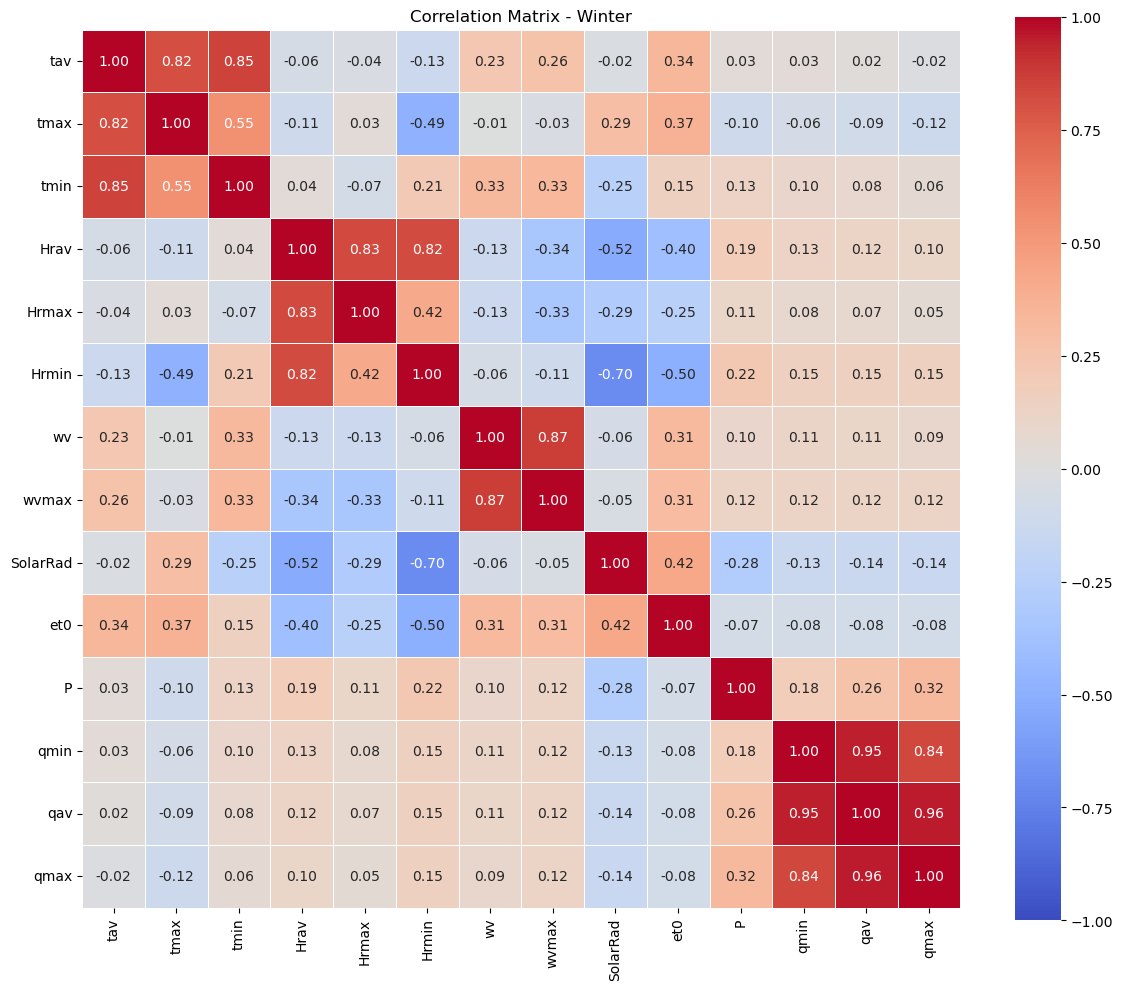


SPRING
Data points: 8271

Correlations with discharge variables:


,qmin,qav,qmax
tav,-0.214143,-0.253014,-0.275320
tmax,-0.236045,-0.281950,-0.308633
tmin,-0.130602,-0.157406,-0.173452
Hrav,0.205308,0.218462,0.220411
Hrmax,0.098528,0.102905,0.099905
Hrmin,0.238028,0.258001,0.254517
wv,-0.065395,-0.077245,-0.070888
wvmax,0.022894,0.029445,0.041679
SolarRad,-0.095646,-0.106502,-0.123906
et0,-0.185362,-0.200199,-0.207210


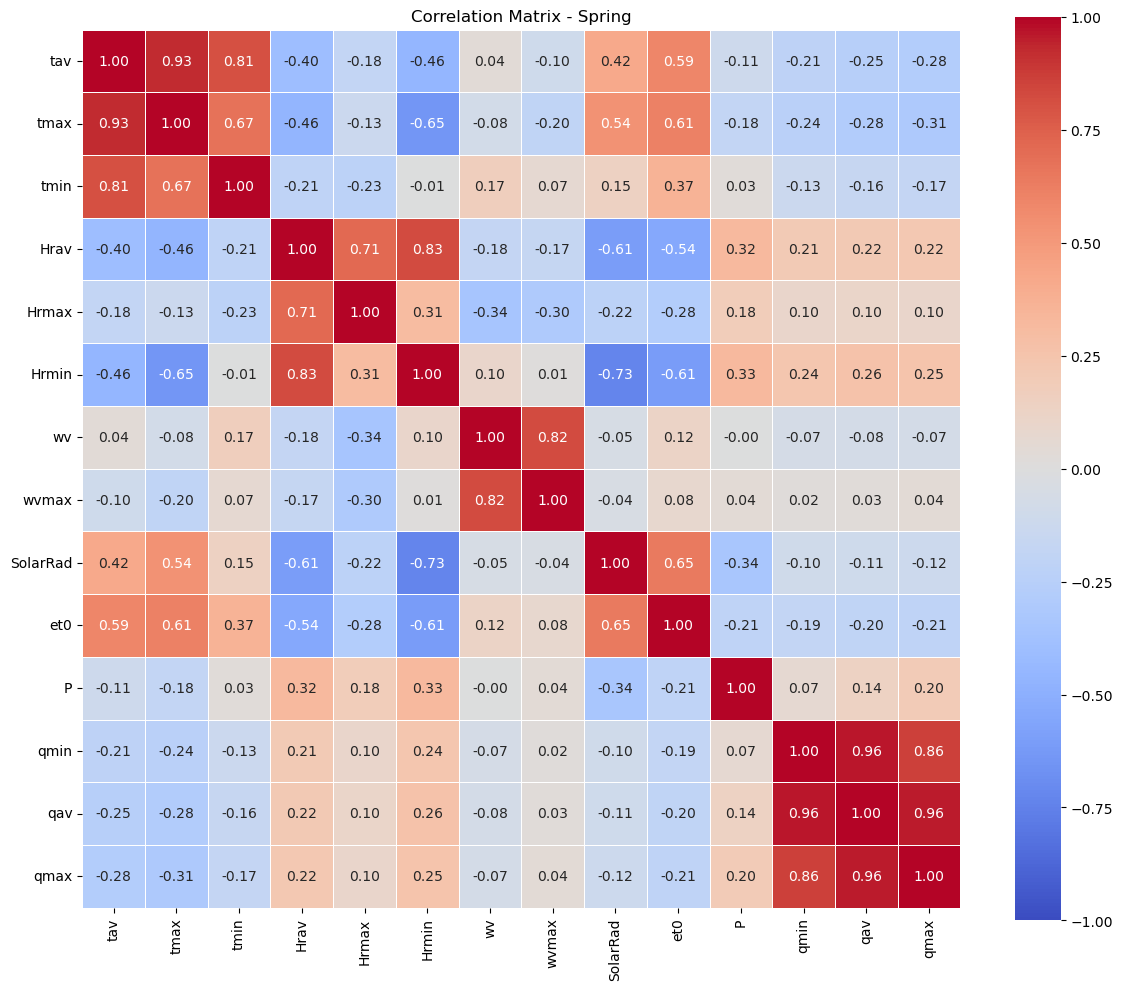


SUMMER
Data points: 8253

Correlations with discharge variables:


,qmin,qav,qmax
tav,-0.404392,-0.419156,-0.430261
tmax,-0.378938,-0.404911,-0.427978
tmin,-0.300140,-0.313259,-0.316204
Hrav,0.208052,0.215911,0.221953
Hrmax,0.115493,0.120417,0.122586
Hrmin,0.238661,0.226552,0.187707
wv,-0.171687,-0.182726,-0.196434
wvmax,-0.017231,-0.024610,-0.021601
SolarRad,-0.069366,-0.077844,-0.086923
et0,-0.274463,-0.286109,-0.300924


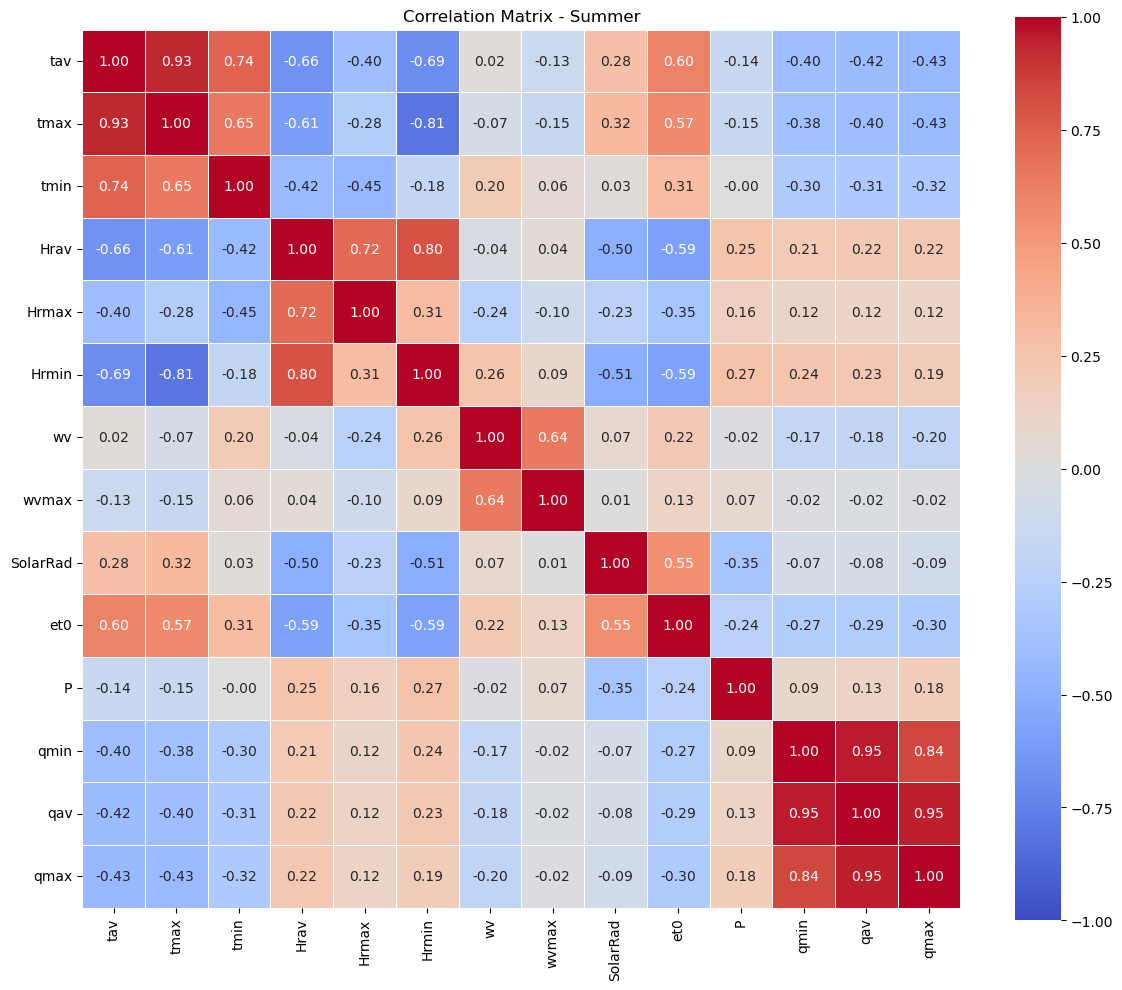


AUTUMN
Data points: 8151

Correlations with discharge variables:


,qmin,qav,qmax
tav,-0.287125,-0.249332,-0.241278
tmax,-0.303381,-0.276680,-0.278827
tmin,-0.190946,-0.164590,-0.158163
Hrav,0.173652,0.162353,0.160468
Hrmax,0.081237,0.076513,0.073435
Hrmin,0.236917,0.207620,0.200855
wv,-0.023439,-0.012140,-0.005786
wvmax,0.022798,0.021919,0.036360
SolarRad,-0.173543,-0.170656,-0.174481
et0,-0.236733,-0.206496,-0.199457


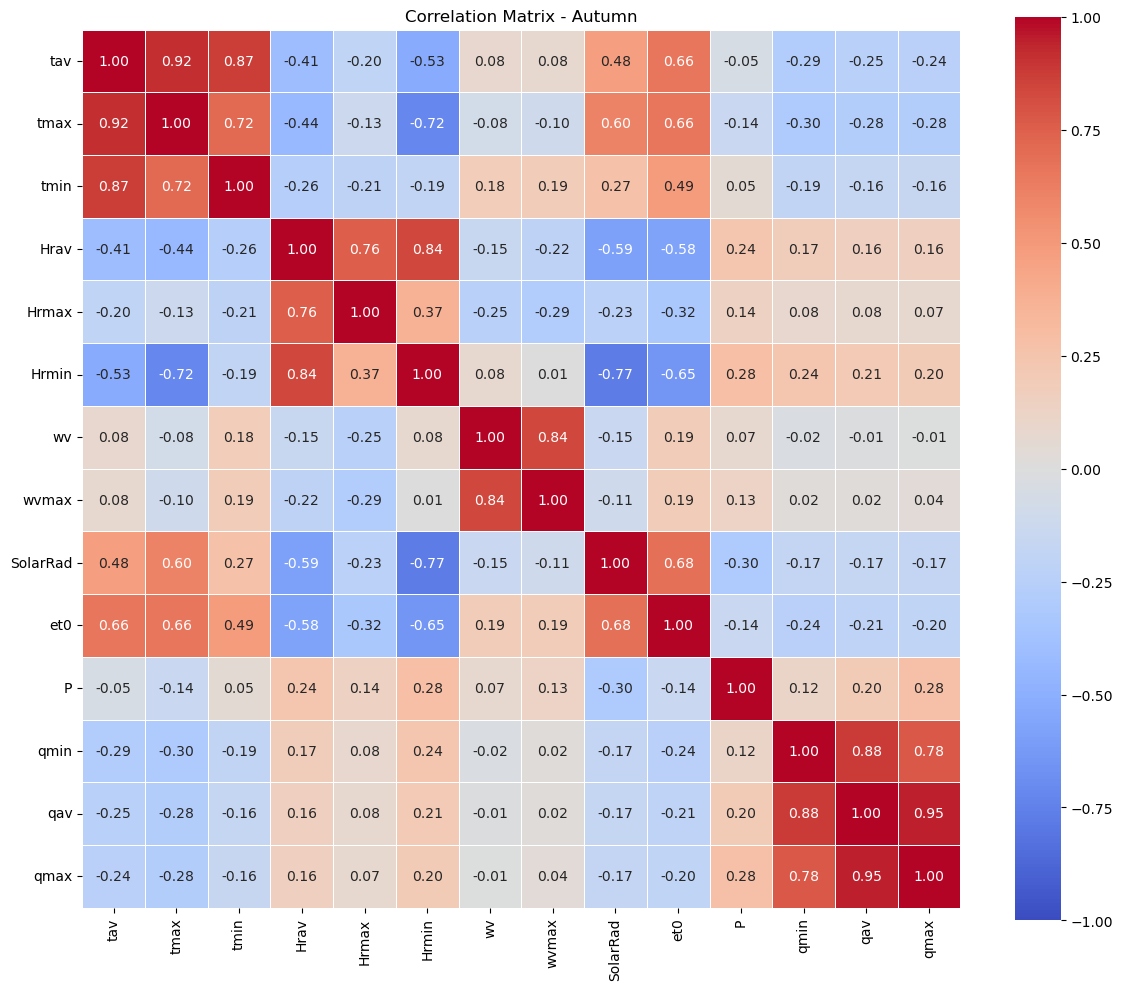

In [8]:
seasons = ['Winter', 'Spring', 'Summer', 'Autumn']
seasonal_correlations = {}

print("="*80)
print("SEASONAL CORRELATION ANALYSIS")
print("="*80)

for season in seasons:
    print(f"\n{'='*80}")
    print(f"{season.upper()}")
    print(f"{'='*80}")
    
    # Filter data for this season
    season_data = global_df[global_df['Season'] == season]
    print(f"Data points: {len(season_data)}")
    
    # Select numeric columns
    available_vars = [v for v in all_vars if v in season_data.columns]
    numeric_df = season_data[available_vars].select_dtypes(include='number')
    
    # Calculate correlation matrix
    corr_matrix = numeric_df.corr()
    seasonal_correlations[season] = corr_matrix
    
    # Display correlation of discharge variables with predictors
    print(f"\nCorrelations with discharge variables:")
    discharge_corr = corr_matrix[discharge_vars].drop(discharge_vars, errors='ignore')
    display(discharge_corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1))
    
    # Plot correlation heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        corr_matrix, 
        annot=True, 
        fmt='.2f', 
        cmap='coolwarm', 
        center=0,
        vmin=-1, 
        vmax=1,
        square=True,
        linewidths=0.5
    )
    plt.title(f'Correlation Matrix - {season}')
    plt.tight_layout()
    plt.show()

## 1.2: Compare Correlations Across Seasons

In [9]:
os.makedirs("3-seasonal_correlations", exist_ok=True)

Correlation with qav (average discharge) across seasons:


,Winter,Spring,Summer,Autumn
tav,0.015697,-0.253014,-0.419156,-0.249332
tmax,-0.086676,-0.281950,-0.404911,-0.276680
tmin,0.084591,-0.157406,-0.313259,-0.164590
Hrav,0.122261,0.218462,0.215911,0.162353
Hrmax,0.071497,0.102905,0.120417,0.076513
Hrmin,0.151683,0.258001,0.226552,0.207620
wv,0.105487,-0.077245,-0.182726,-0.012140
wvmax,0.123230,0.029445,-0.024610,0.021919
SolarRad,-0.139871,-0.106502,-0.077844,-0.170656
et0,-0.079299,-0.200199,-0.286109,-0.206496


<Figure size 1400x800 with 0 Axes>

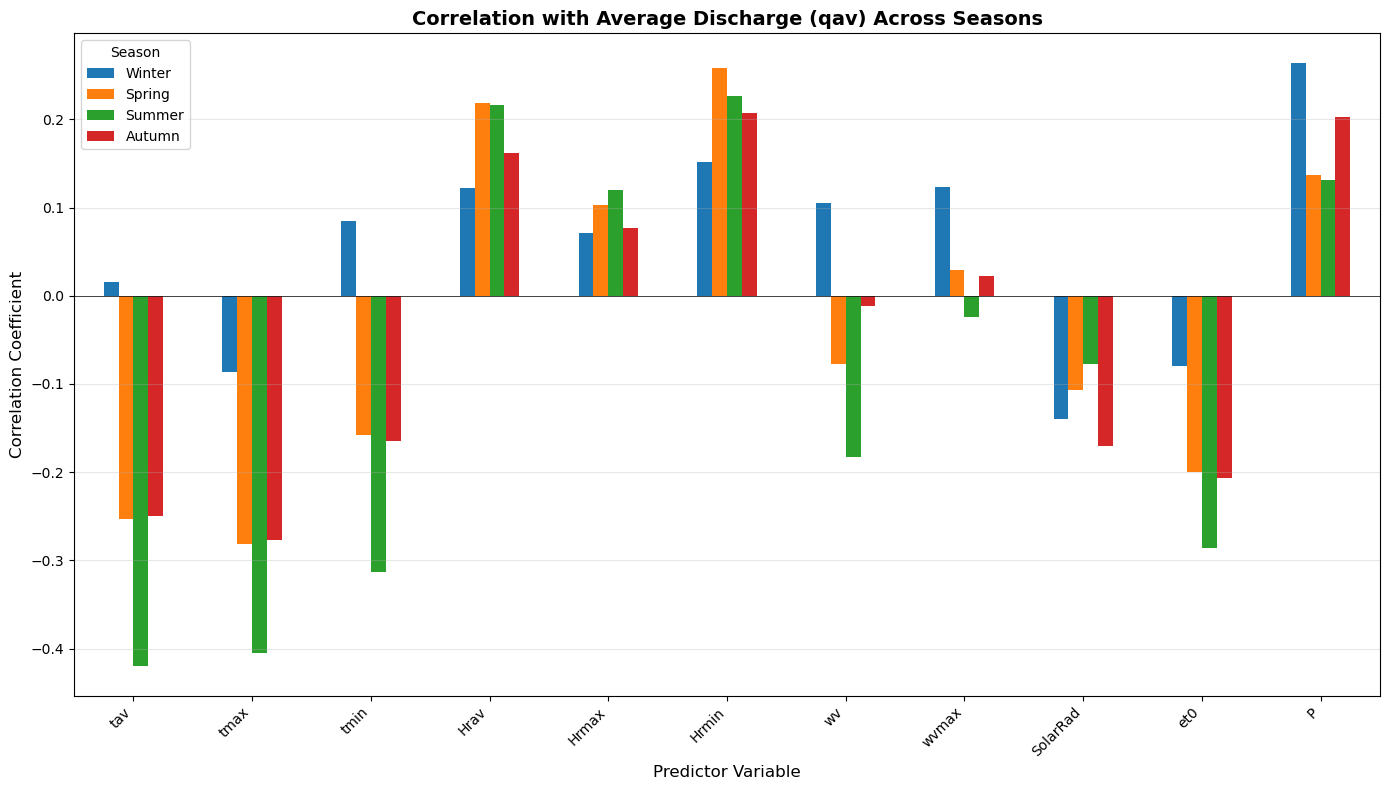


STRONGEST PREDICTORS OF qav BY SEASON

Winter:
  Top positive correlations:
    P: 0.263
    Hrmin: 0.152
    wvmax: 0.123
  Top negative correlations:
    SolarRad: -0.140
    tmax: -0.087
    et0: -0.079

Spring:
  Top positive correlations:
    Hrmin: 0.258
    Hrav: 0.218
    P: 0.137
  Top negative correlations:
    tmax: -0.282
    tav: -0.253
    et0: -0.200

Summer:
  Top positive correlations:
    Hrmin: 0.227
    Hrav: 0.216
    P: 0.131
  Top negative correlations:
    tav: -0.419
    tmax: -0.405
    tmin: -0.313

Autumn:
  Top positive correlations:
    Hrmin: 0.208
    P: 0.203
    Hrav: 0.162
  Top negative correlations:
    tmax: -0.277
    tav: -0.249
    et0: -0.206


In [10]:
# Extract correlations with qav for each season
qav_correlations_by_season = pd.DataFrame()

for season in seasons:
    if 'qav' in seasonal_correlations[season].columns:
        qav_corr = seasonal_correlations[season]['qav'].drop(discharge_vars, errors='ignore')
        qav_correlations_by_season[season] = qav_corr

print("Correlation with qav (average discharge) across seasons:")
display(qav_correlations_by_season.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1, axis=None))

# Plot comparison
plt.figure(figsize=(14, 8))
qav_correlations_by_season.plot(kind='bar', figsize=(14, 8))
plt.title('Correlation with Average Discharge (qav) Across Seasons', fontsize=14, fontweight='bold')
plt.xlabel('Predictor Variable', fontsize=12)
plt.ylabel('Correlation Coefficient', fontsize=12)
plt.legend(title='Season', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig("3-seasonal_correlations/qav_correlations_by_season.png", dpi=300)
plt.show()

# Identify strongest predictors per season
print("\n" + "="*80)
print("STRONGEST PREDICTORS OF qav BY SEASON")
print("="*80)
for season in seasons:
    if season in qav_correlations_by_season.columns:
        top_positive = qav_correlations_by_season[season].nlargest(3)
        top_negative = qav_correlations_by_season[season].nsmallest(3)
        
        print(f"\n{season}:")
        print("  Top positive correlations:")
        for var, corr in top_positive.items():
            print(f"    {var}: {corr:.3f}")
        print("  Top negative correlations:")
        for var, corr in top_negative.items():
            print(f"    {var}: {corr:.3f}")

## 1.3: Correlation Analysis by Month

More granular analysis at monthly level.

In [11]:
# Get unique months in order
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
months_in_data = [m for m in month_order if m in global_df['Month'].unique()]

print(f"Analyzing {len(months_in_data)} months: {months_in_data}")

Analyzing 12 months: ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']


In [12]:
monthly_correlations = {}

# Calculate correlations for each month (displaying only key results)
for month in months_in_data:
    month_data = global_df[global_df['Month'] == month]
    
    if len(month_data) < 50:  # Skip months with very little data
        print(f"Skipping {month} - insufficient data ({len(month_data)} points)")
        continue
    
    available_vars = [v for v in all_vars if v in month_data.columns]
    numeric_df = month_data[available_vars].select_dtypes(include='number')
    corr_matrix = numeric_df.corr()
    monthly_correlations[month] = corr_matrix

print(f"\nCalculated correlations for {len(monthly_correlations)} months")


Calculated correlations for 12 months


In [13]:
# Extract correlations with qav for each month
qav_correlations_by_month = pd.DataFrame()

for month in months_in_data:
    if month in monthly_correlations and 'qav' in monthly_correlations[month].columns:
        qav_corr = monthly_correlations[month]['qav'].drop(discharge_vars, errors='ignore')
        qav_correlations_by_month[month] = qav_corr

print("Correlation with qav (average discharge) across months:")
display(qav_correlations_by_month.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1, axis=None))

Correlation with qav (average discharge) across months:


,January,February,March,April,May,June,July,August,September,October,November,December
tav,0.074841,-0.042372,-0.104339,-0.271532,-0.415581,-0.462132,-0.479324,-0.388580,-0.303802,-0.356480,-0.096968,0.001594
tmax,-0.041104,-0.169092,-0.152241,-0.294829,-0.428995,-0.460746,-0.436401,-0.362361,-0.304146,-0.387702,-0.148505,-0.064747
tmin,0.143107,0.073185,-0.006639,-0.171368,-0.313237,-0.355870,-0.327670,-0.252249,-0.178175,-0.204779,-0.020016,0.032452
Hrav,0.100747,0.157923,0.184638,0.235802,0.245206,0.192881,0.256734,0.186791,0.185773,0.209681,0.055803,0.096372
Hrmax,0.061156,0.088541,0.106719,0.149551,0.070129,0.080740,0.173387,0.083591,0.096857,0.117869,0.015131,0.062292
Hrmin,0.148993,0.242032,0.215660,0.209289,0.300061,0.265050,0.165252,0.095325,0.144836,0.235037,0.132733,0.072755
wv,0.168966,0.114548,0.089972,-0.130072,-0.207842,-0.212052,-0.244462,-0.130471,-0.084525,-0.036334,0.006480,0.074423
wvmax,0.173407,0.141876,0.070536,-0.031137,-0.042734,-0.019309,0.037819,-0.006166,0.023083,0.029108,0.025378,0.105617
SolarRad,-0.119943,-0.161096,-0.128376,-0.121945,-0.124374,-0.083019,-0.047097,-0.118242,-0.093899,-0.152008,-0.100977,-0.120451
et0,-0.040765,-0.112765,-0.143434,-0.187453,-0.283823,-0.308058,-0.345440,-0.283626,-0.209862,-0.265508,-0.070894,-0.039711


In [14]:
os.makedirs("3-monthly_correlations", exist_ok=True)

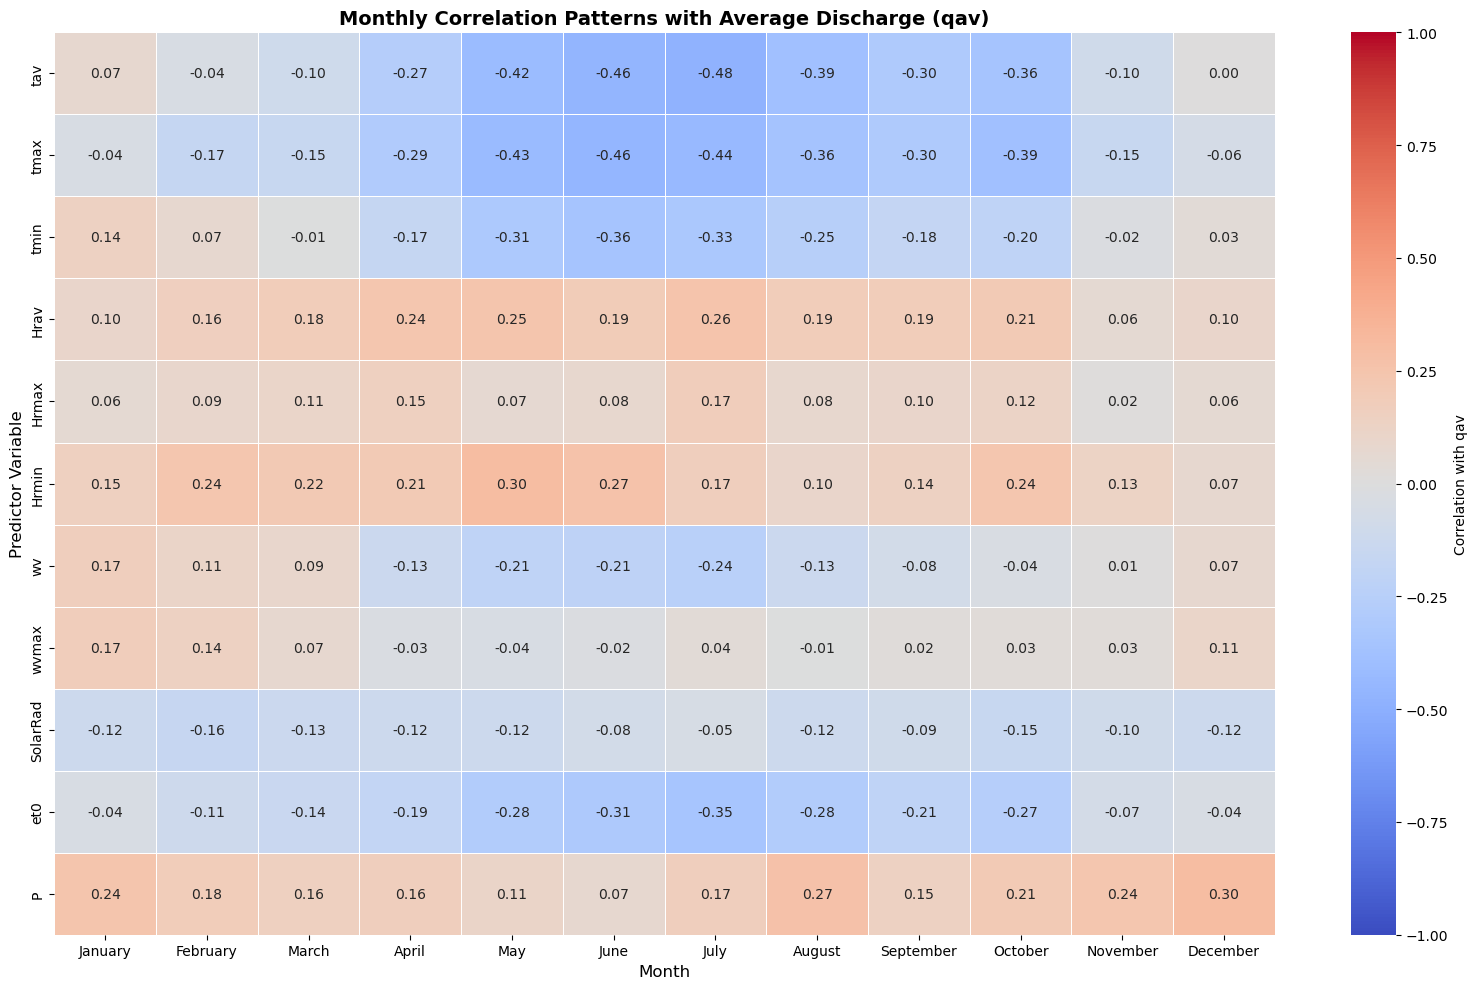

In [15]:
# Plot monthly correlations as heatmap
plt.figure(figsize=(16, 10))
sns.heatmap(
    qav_correlations_by_month,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Correlation with qav'},
    linewidths=0.5
)
plt.title('Monthly Correlation Patterns with Average Discharge (qav)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Predictor Variable', fontsize=12)
plt.tight_layout()
plt.savefig("3-monthly_correlations/qav_monthly_correlations_heatmap.png", dpi=300)
plt.show()

In [16]:
os.makedirs("3-key_variable_correlations", exist_ok=True)

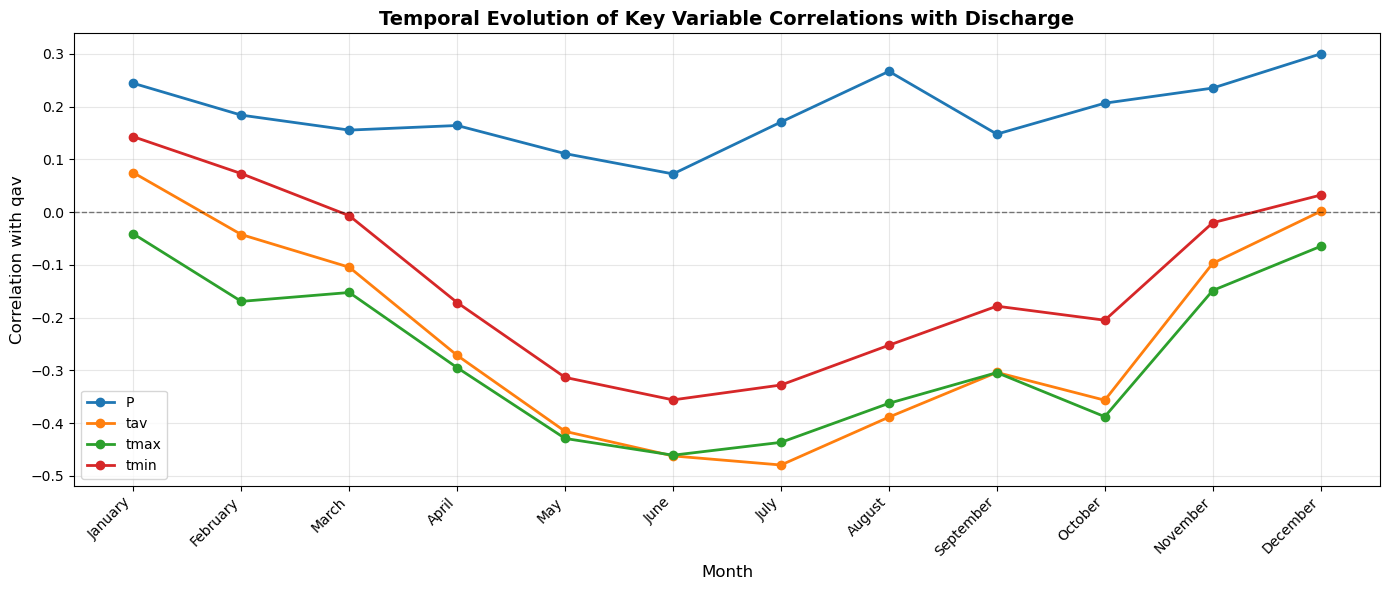

In [17]:
# Focus on key variables: P, soil_moisture, and temperature
key_vars = ['P', 'soil_moisture', 'tav', 'tmax', 'tmin']
key_vars_available = [v for v in key_vars if v in qav_correlations_by_month.index]

# Plot time series of correlations
plt.figure(figsize=(14, 6))
for var in key_vars_available:
    plt.plot(qav_correlations_by_month.columns, 
             qav_correlations_by_month.loc[var], 
             marker='o', 
             linewidth=2, 
             label=var)

plt.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Correlation with qav', fontsize=12)
plt.title('Temporal Evolution of Key Variable Correlations with Discharge', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("3-key_variable_correlations/key_vars_qav_correlation_timeseries.png", dpi=300)
plt.show()

# Part 2: Seasonal Clustering Analysis

Perform clustering analysis for each season to see if basin groupings change over time.

## 2.1: Aggregate Basin Statistics by Season

In [18]:
def calculate_basin_stats_for_period(data_dict, period_name):
    """
    Calculate discharge statistics for each basin for a given time period.
    """
    basin_stats = []
    
    for basin_name, df in data_dict.items():
        if len(df) < 10:  # Skip if too little data
            continue
            
        stats = {
            'Basin': basin_name,
            'Period': period_name,
            'qmin_mean': df['qmin'].mean(),
            'qmin_std': df['qmin'].std(),
            'qmin_median': df['qmin'].median(),
            'qav_mean': df['qav'].mean(),
            'qav_std': df['qav'].std(),
            'qav_median': df['qav'].median(),
            'qmax_mean': df['qmax'].mean(),
            'qmax_std': df['qmax'].std(),
            'qmax_median': df['qmax'].median(),
            'P_mean': df['P'].mean(),
            'P_std': df['P'].std(),
            'soil_moisture_mean': df['soil_moisture'].mean() if 'soil_moisture' in df.columns else np.nan,
            'n_observations': len(df)
        }
        basin_stats.append(stats)
    
    return pd.DataFrame(basin_stats)

# Calculate seasonal statistics for each basin
seasonal_basin_stats = {}

for season in seasons:
    # Create dictionary of basin data for this season
    season_basin_dict = {}
    for basin_name, df in join_dict.items():
        season_data = df[df['Season'] == season]
        if len(season_data) > 0:
            season_basin_dict[basin_name] = season_data
    
    # Calculate statistics
    stats_df = calculate_basin_stats_for_period(season_basin_dict, season)
    seasonal_basin_stats[season] = stats_df
    
    print(f"{season}: {len(stats_df)} basins with data")

# Display sample
print("\nSample statistics for Winter:")
display(seasonal_basin_stats['Winter'].head())

Winter: 18 basins with data
Spring: 18 basins with data
Summer: 18 basins with data
Autumn: 18 basins with data

Sample statistics for Winter:


,Basin,Period,qmin_mean,qmin_std,qmin_median,qav_mean,qav_std,qav_median,qmax_mean,qmax_std,qmax_median,P_mean,P_std,soil_moisture_mean,n_observations
0,Tiron-with-outliers,Winter,5.281856,3.753809,4.9940,5.746704,4.143682,5.2750,6.339690,4.800010,5.750,2.011504,4.990745,NaN,452
1,Oroncillo-with-outliers,Winter,1.109885,1.002516,0.7500,1.277914,1.385588,0.7685,1.526577,2.103882,0.860,1.810177,4.124728,NaN,452
2,Rudron-with-outliers,Winter,5.876697,4.285886,4.6780,6.386571,4.995695,4.7150,6.956770,5.949755,5.170,1.498053,3.812353,NaN,452
3,Larraun-with-outliers,Winter,3.563737,6.763050,1.5355,5.327434,9.238349,2.0000,7.595113,12.507666,2.729,8.091593,18.302679,NaN,452
4,Zatoya-with-outliers,Winter,0.853040,1.173763,0.7430,1.023894,1.177174,0.7600,1.378186,2.061703,0.780,5.066150,10.696058,NaN,452


## 2.2: K-Means Clustering by Season

In [19]:
os.makedirs("3-seasonal_clusters", exist_ok=True)

SEASONAL K-MEANS CLUSTERING (k=3)

Winter:
  Cluster 0: ['Oroncillo-with-outliers', 'Zatoya-with-outliers', 'Flamisell-with-outliers', 'Vallfarrera-with-outliers', 'Yanguas-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Deza-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']
  Cluster 1: ['Tiron-with-outliers', 'Rudron-with-outliers', 'Larraun-with-outliers', 'Garona-with-outliers', 'Urrobi-with-outliers', 'Ubagua-with-outliers']
  Cluster 2: ['Nela-with-outliers']


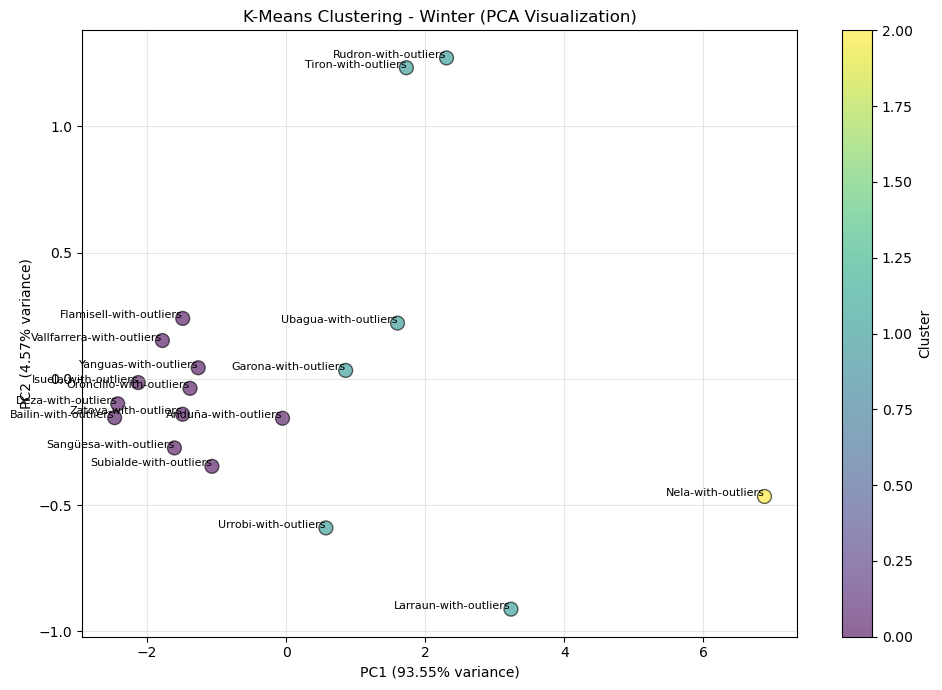


Spring:
  Cluster 0: ['Tiron-with-outliers', 'Rudron-with-outliers', 'Larraun-with-outliers', 'Yanguas-with-outliers', 'Nela-with-outliers', 'Ubagua-with-outliers']
  Cluster 1: ['Garona-with-outliers']
  Cluster 2: ['Oroncillo-with-outliers', 'Zatoya-with-outliers', 'Flamisell-with-outliers', 'Vallfarrera-with-outliers', 'Urrobi-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Deza-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']


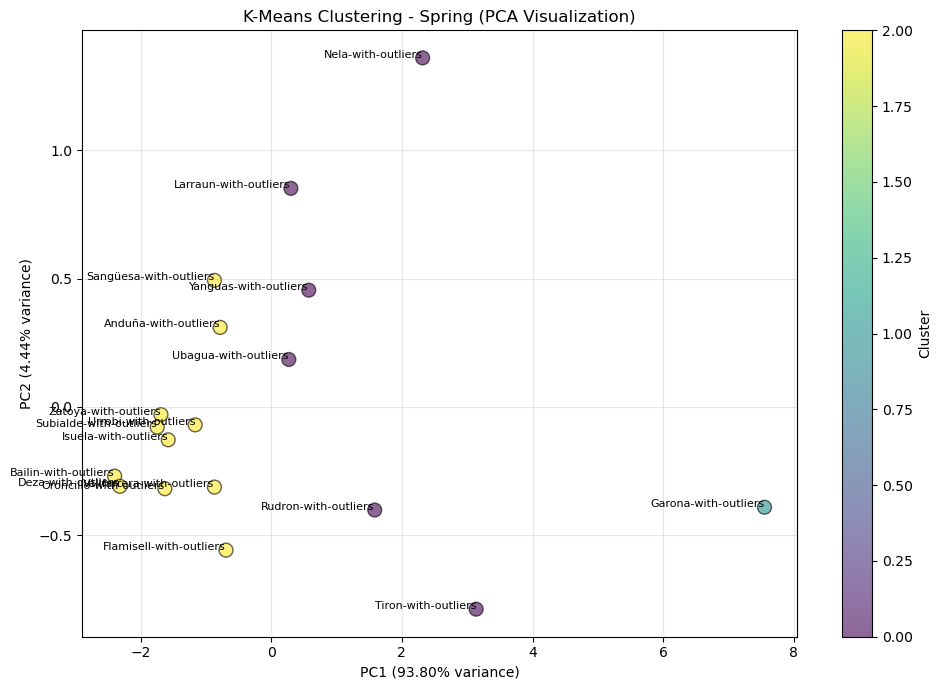


Summer:
  Cluster 0: ['Tiron-with-outliers', 'Rudron-with-outliers', 'Larraun-with-outliers', 'Flamisell-with-outliers', 'Vallfarrera-with-outliers', 'Nela-with-outliers']
  Cluster 1: ['Garona-with-outliers']
  Cluster 2: ['Oroncillo-with-outliers', 'Zatoya-with-outliers', 'Yanguas-with-outliers', 'Urrobi-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Deza-with-outliers', 'Ubagua-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']


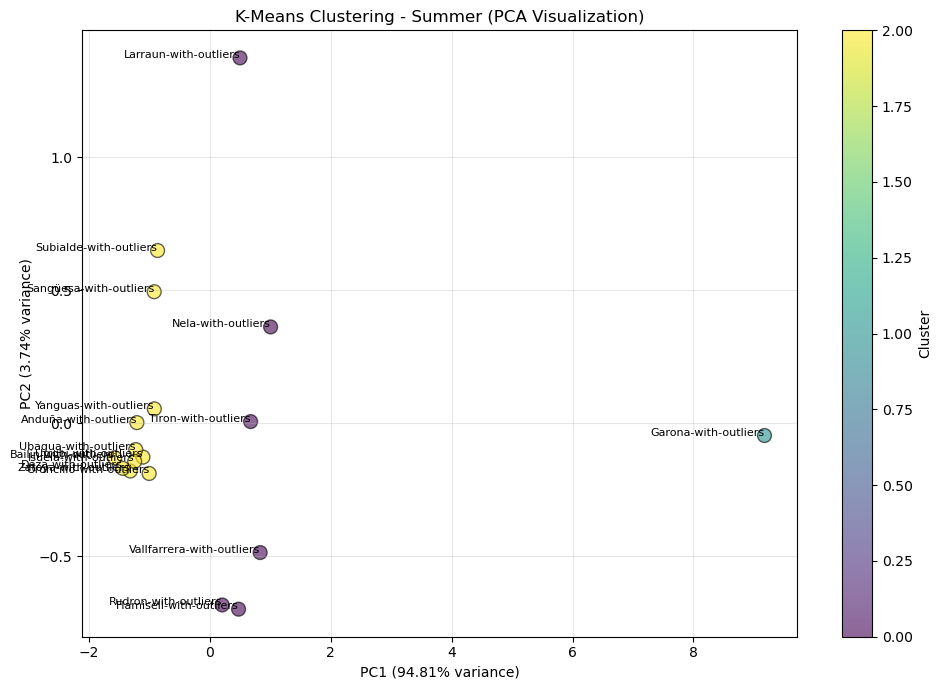


Autumn:
  Cluster 0: ['Oroncillo-with-outliers', 'Zatoya-with-outliers', 'Vallfarrera-with-outliers', 'Yanguas-with-outliers', 'Urrobi-with-outliers', 'Anduña-with-outliers', 'Bailin-with-outliers', 'Deza-with-outliers', 'Ubagua-with-outliers', 'Isuela-with-outliers', 'Subialde-with-outliers', 'Sangüesa-with-outliers']
  Cluster 1: ['Tiron-with-outliers', 'Rudron-with-outliers', 'Flamisell-with-outliers']
  Cluster 2: ['Larraun-with-outliers', 'Garona-with-outliers', 'Nela-with-outliers']


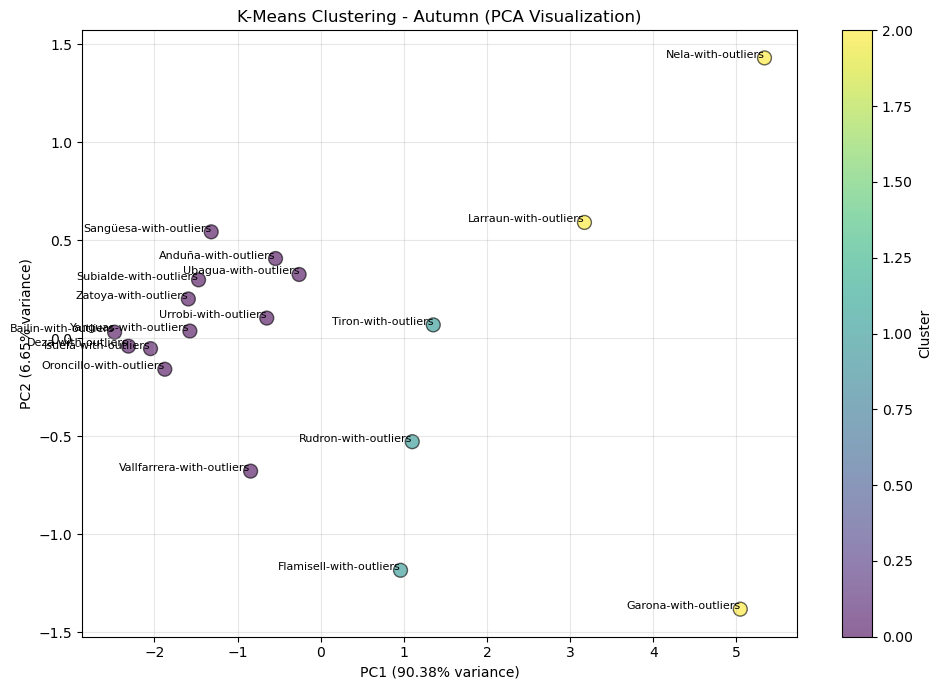

In [20]:
# Perform K-means clustering for each season
k_clusters = 3  # Use 3 clusters as in original analysis
seasonal_clusters = {}

# Features to use for clustering
cluster_features = ['qmin_mean', 'qmin_std', 'qav_mean', 'qav_std', 'qmax_mean', 'qmax_std']

print("="*80)
print("SEASONAL K-MEANS CLUSTERING (k=3)")
print("="*80)

for season in seasons:
    print(f"\n{season}:")
    
    stats_df = seasonal_basin_stats[season].copy()
    
    # Prepare features
    X = stats_df[cluster_features].values
    basins = stats_df['Basin'].values
    
    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # K-means clustering
    kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    stats_df['Cluster'] = cluster_labels
    seasonal_clusters[season] = stats_df
    
    # Display cluster assignments
    for cluster_id in range(k_clusters):
        basins_in_cluster = stats_df[stats_df['Cluster'] == cluster_id]['Basin'].tolist()
        print(f"  Cluster {cluster_id}: {basins_in_cluster}")
    
    # PCA for visualization
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    # Plot
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(
        X_pca[:, 0], 
        X_pca[:, 1], 
        c=cluster_labels, 
        cmap='viridis', 
        s=100, 
        alpha=0.6,
        edgecolors='black'
    )
    
    # Annotate basins
    for i, basin in enumerate(basins):
        plt.annotate(basin, (X_pca[i, 0], X_pca[i, 1]), fontsize=8, ha='right')
    
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
    plt.title(f'K-Means Clustering - {season} (PCA Visualization)')
    plt.colorbar(scatter, label='Cluster')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"3-seasonal_clusters/{season}_kmeans_pca.png", dpi=300)
    plt.show()

## 2.3: Compare Cluster Assignments Across Seasons

In [21]:
# Create comparison table
cluster_comparison = pd.DataFrame()

for season in seasons:
    cluster_comparison[season] = seasonal_clusters[season].set_index('Basin')['Cluster']

print("Cluster assignments across seasons:")
display(cluster_comparison)

# Calculate cluster stability (how often basins stay in same cluster)
print("\nCluster Stability Analysis:")
print("Number of different clusters each basin belongs to across seasons:")
n_different_clusters = cluster_comparison.nunique(axis=1)
print(n_different_clusters.value_counts().sort_index())

print("\nBasins that change clusters across seasons:")
changing_basins = n_different_clusters[n_different_clusters > 1]
for basin, n_clusters in changing_basins.items():
    print(f"  {basin}: {n_clusters} different clusters")
    print(f"    {cluster_comparison.loc[basin].to_dict()}")

Cluster assignments across seasons:


,Winter,Spring,Summer,Autumn
Basin,,,,
Tiron-with-outliers,1,0,0,1
Oroncillo-with-outliers,0,2,2,0
Rudron-with-outliers,1,0,0,1
Larraun-with-outliers,1,0,0,2
Zatoya-with-outliers,0,2,2,0
Flamisell-with-outliers,0,2,0,1
Vallfarrera-with-outliers,0,2,0,0
Yanguas-with-outliers,0,0,2,0
Garona-with-outliers,1,1,1,2



Cluster Stability Analysis:
Number of different clusters each basin belongs to across seasons:
2    14
3     4
Name: count, dtype: int64

Basins that change clusters across seasons:
  Tiron-with-outliers: 2 different clusters
    {'Winter': 1, 'Spring': 0, 'Summer': 0, 'Autumn': 1}
  Oroncillo-with-outliers: 2 different clusters
    {'Winter': 0, 'Spring': 2, 'Summer': 2, 'Autumn': 0}
  Rudron-with-outliers: 2 different clusters
    {'Winter': 1, 'Spring': 0, 'Summer': 0, 'Autumn': 1}
  Larraun-with-outliers: 3 different clusters
    {'Winter': 1, 'Spring': 0, 'Summer': 0, 'Autumn': 2}
  Zatoya-with-outliers: 2 different clusters
    {'Winter': 0, 'Spring': 2, 'Summer': 2, 'Autumn': 0}
  Flamisell-with-outliers: 3 different clusters
    {'Winter': 0, 'Spring': 2, 'Summer': 0, 'Autumn': 1}
  Vallfarrera-with-outliers: 2 different clusters
    {'Winter': 0, 'Spring': 2, 'Summer': 0, 'Autumn': 0}
  Yanguas-with-outliers: 2 different clusters
    {'Winter': 0, 'Spring': 0, 'Summer': 2, 'A

In [22]:
os.makedirs("3-cluster_changes", exist_ok=True)

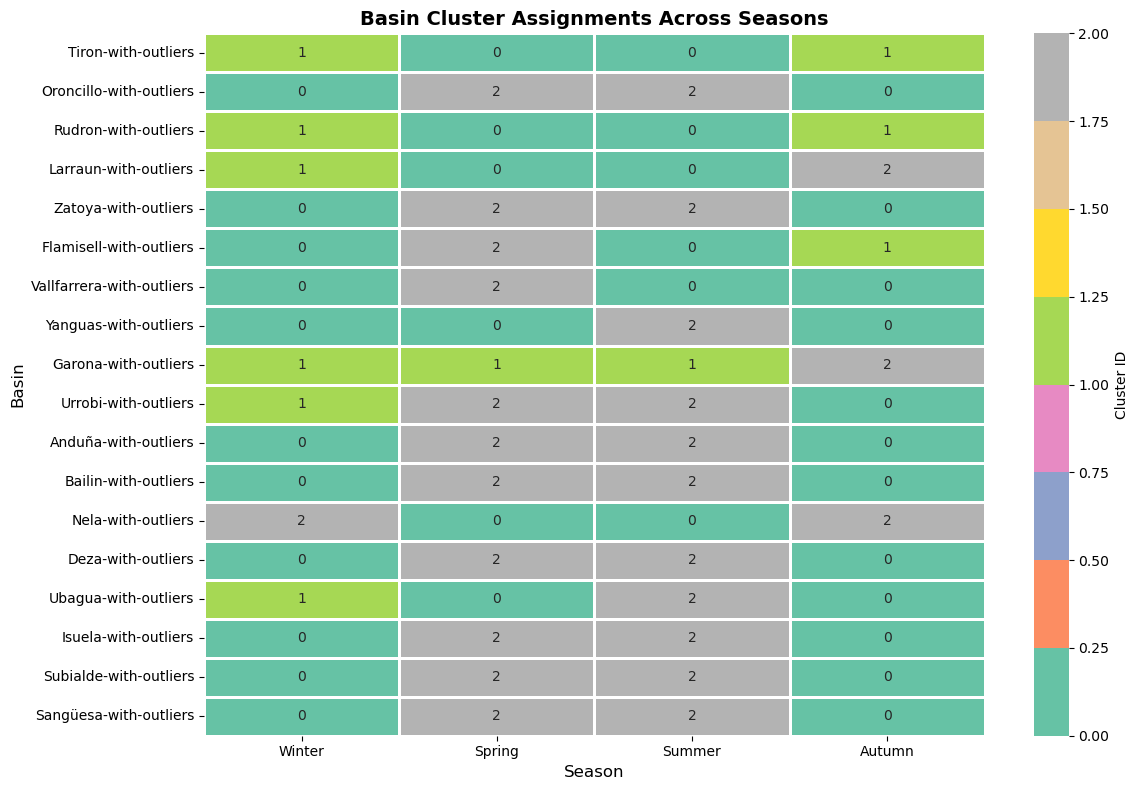

In [23]:
# Visualize cluster changes
fig, ax = plt.subplots(figsize=(12, 8))

# Create heatmap of cluster assignments
sns.heatmap(
    cluster_comparison,
    annot=True,
    fmt='d',
    cmap='Set2',
    cbar_kws={'label': 'Cluster ID'},
    linewidths=1,
    ax=ax
)
plt.title('Basin Cluster Assignments Across Seasons', fontsize=14, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Basin', fontsize=12)
plt.tight_layout()
plt.savefig("3-cluster_changes/basin_cluster_assignments.png", dpi=300)
plt.show()

## 2.4: Seasonal Discharge Patterns

Analyze how discharge characteristics change across seasons.

In [24]:
os.makedirs("3-seasonal_patterns", exist_ok=True)

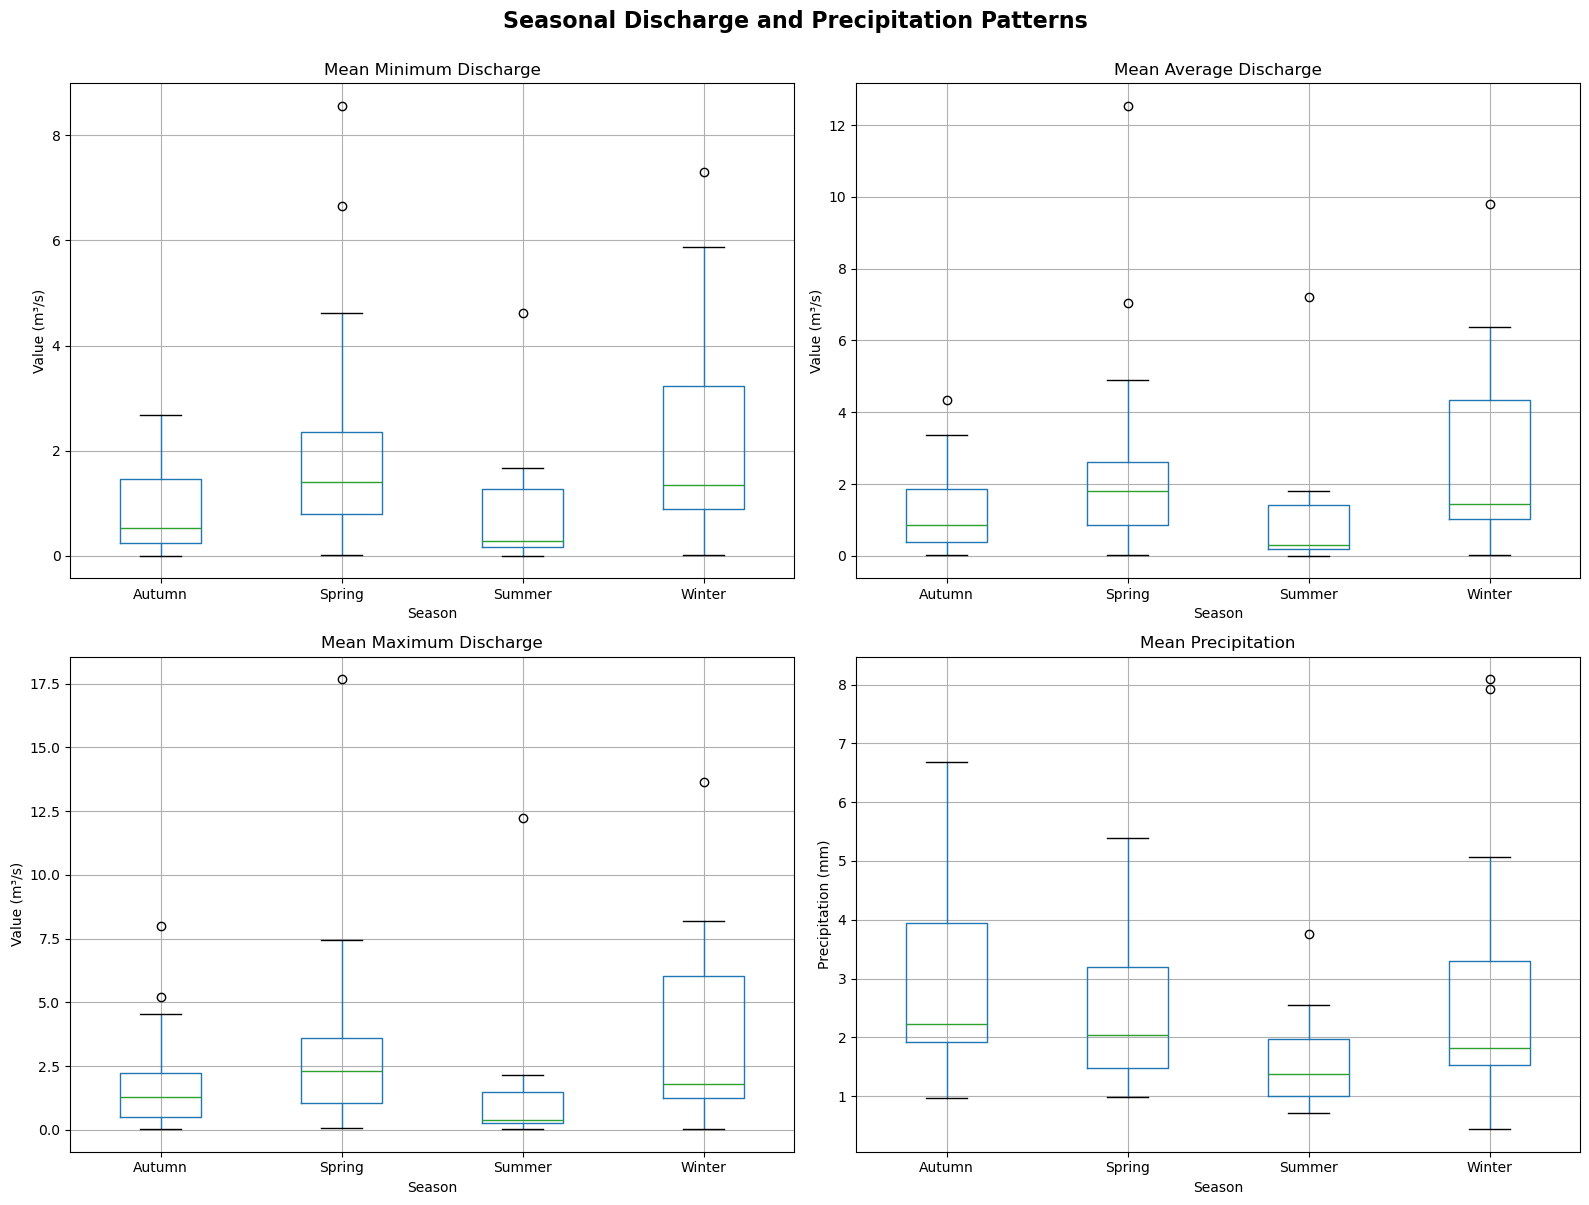

In [25]:
# Combine all seasonal statistics
all_seasonal_stats = pd.concat(seasonal_basin_stats.values(), ignore_index=True)

# Plot discharge patterns across seasons
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

discharge_metrics = ['qmin_mean', 'qav_mean', 'qmax_mean', 'P_mean']
metric_labels = ['Mean Minimum Discharge', 'Mean Average Discharge', 'Mean Maximum Discharge', 'Mean Precipitation']

for idx, (metric, label) in enumerate(zip(discharge_metrics, metric_labels)):
    # Box plot by season
    all_seasonal_stats.boxplot(column=metric, by='Period', ax=axes[idx])
    axes[idx].set_title(label)
    axes[idx].set_xlabel('Season')
    axes[idx].set_ylabel('Value (m³/s)' if 'P' not in metric else 'Precipitation (mm)')
    axes[idx].get_figure().suptitle('')  # Remove automatic title

plt.suptitle('Seasonal Discharge and Precipitation Patterns', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig("3-seasonal_patterns/seasonal_discharge_precipitation.png", dpi=300)
plt.show()

In [26]:
# Statistical summary by season
seasonal_summary = all_seasonal_stats.groupby('Period')[discharge_metrics].agg(['mean', 'std', 'median'])

print("Statistical Summary by Season:")
display(seasonal_summary)

Statistical Summary by Season:


qmin_mean                      qav_mean                     qmax_mean  \
            mean       std    median      mean       std    median      mean   
Period                                                                         
Autumn  0.885123  0.817422  0.540077  1.247166  1.233162  0.872750  1.881018   
Spring  2.238204  2.307812  1.407513  2.729415  3.040693  1.798826  3.420669   
Summer  0.793208  1.112016  0.276122  1.008210  1.668384  0.318084  1.432403   
Winter  2.228602  2.104848  1.343654  2.788680  2.646675  1.443320  3.706537   

                              P_mean                      
             std    median      mean       std    median  
Period                                                    
Autumn  2.095293  1.297616  2.928175  1.607216  2.230837  
Spring  4.085246  2.306391  2.456339  1.247274  2.033696  
Summer  2.794371  0.398096  1.575328  0.801630  1.370479  
Winter  3.639184  1.786887  2.748052  2.299540  1.809292

# Part 3: Monthly Clustering Analysis (Summary)

Perform clustering at monthly resolution for more detailed temporal patterns.

In [27]:
# Calculate monthly statistics (similar to seasonal)
monthly_basin_stats = {}

for month in months_in_data:
    month_basin_dict = {}
    for basin_name, df in join_dict.items():
        month_data = df[df['Month'] == month]
        if len(month_data) > 0:
            month_basin_dict[basin_name] = month_data
    
    stats_df = calculate_basin_stats_for_period(month_basin_dict, month)
    if len(stats_df) >= 10:  # Only keep months with sufficient basins
        monthly_basin_stats[month] = stats_df

print(f"Monthly statistics calculated for {len(monthly_basin_stats)} months")

Monthly statistics calculated for 12 months


In [28]:
# Perform clustering for each month
monthly_clusters = {}

for month in months_in_data:
    if month not in monthly_basin_stats:
        continue
        
    stats_df = monthly_basin_stats[month].copy()
    
    # Prepare features
    X = stats_df[cluster_features].values
    
    # Standardize and cluster
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    stats_df['Cluster'] = cluster_labels
    monthly_clusters[month] = stats_df

print(f"Clustering completed for {len(monthly_clusters)} months")

Clustering completed for 12 months


Monthly cluster assignments:


,January,February,March,April,May,June,July,August,September,October,November,December
Basin,,,,,,,,,,,,
Tiron-with-outliers,1,1,2,1,0,0,2,1,1,2,2,1
Oroncillo-with-outliers,0,0,0,0,2,2,1,1,1,0,1,0
Rudron-with-outliers,1,1,2,2,0,0,2,1,1,2,2,1
Larraun-with-outliers,2,1,1,2,0,0,1,2,0,2,0,1
Zatoya-with-outliers,0,0,0,0,2,2,1,1,1,0,1,0
Flamisell-with-outliers,0,0,0,0,0,0,2,0,0,2,2,0
Vallfarrera-with-outliers,0,0,0,0,0,0,2,0,1,0,1,0
Yanguas-with-outliers,0,0,1,2,2,2,1,1,1,0,1,0
Garona-with-outliers,1,1,1,1,1,1,0,0,2,1,2,1


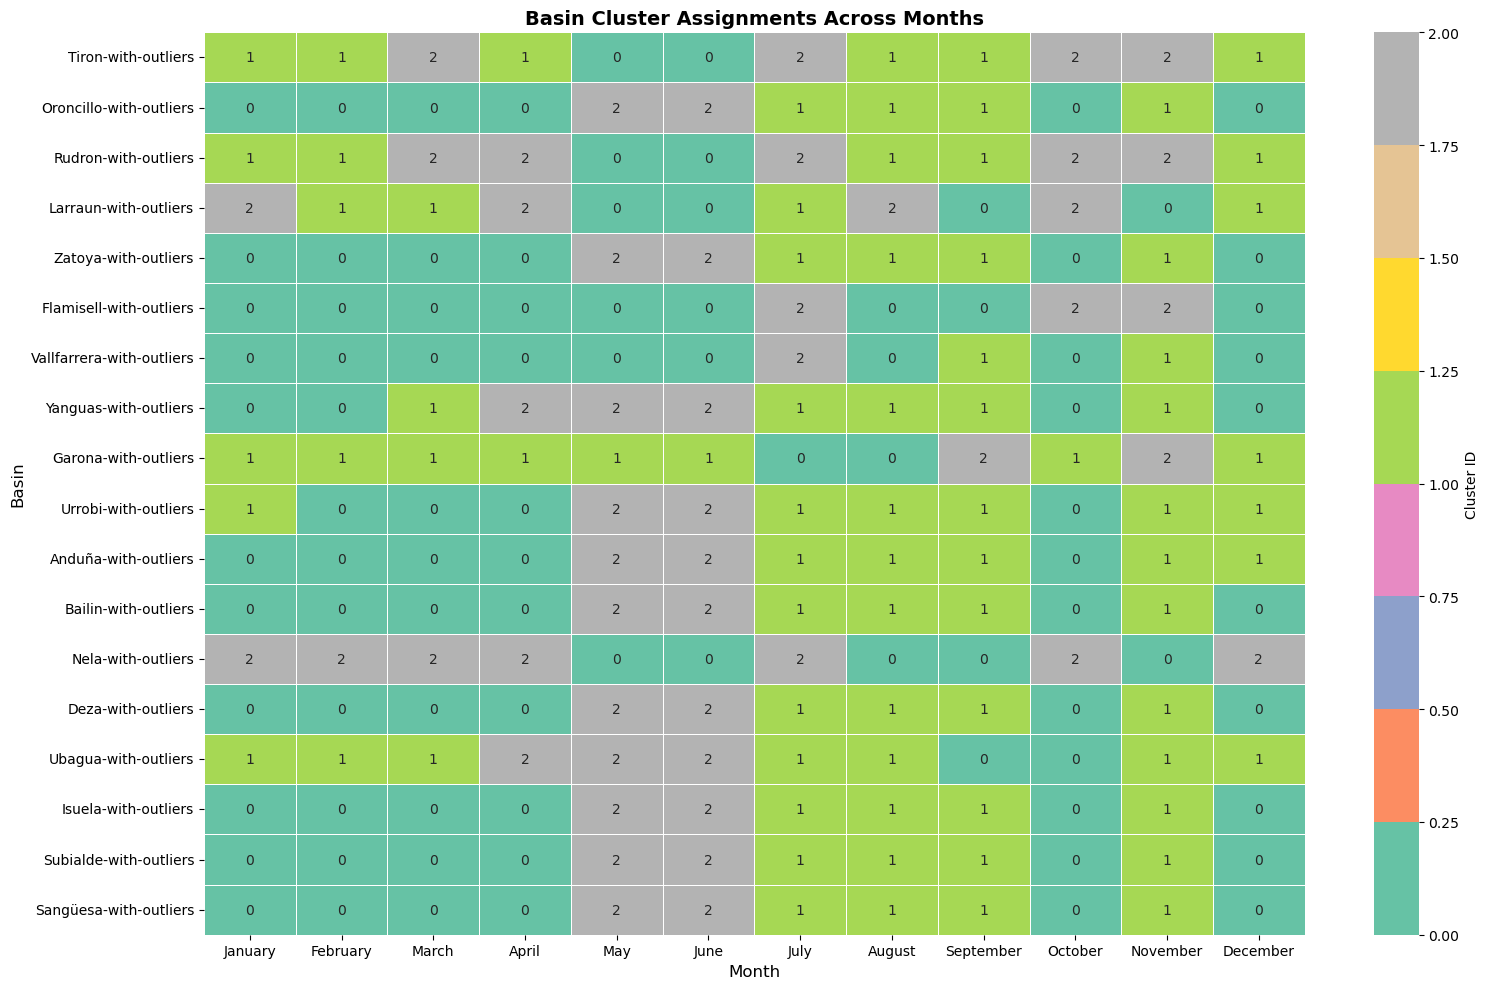

In [29]:
# Create monthly cluster comparison
monthly_cluster_comparison = pd.DataFrame()

for month in months_in_data:
    if month in monthly_clusters:
        monthly_cluster_comparison[month] = monthly_clusters[month].set_index('Basin')['Cluster']

print("Monthly cluster assignments:")
display(monthly_cluster_comparison)

# Visualize as heatmap
fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(
    monthly_cluster_comparison,
    annot=True,
    fmt='g',
    cmap='Set2',
    cbar_kws={'label': 'Cluster ID'},
    linewidths=0.5,
    ax=ax
)
plt.title('Basin Cluster Assignments Across Months', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Basin', fontsize=12)
plt.tight_layout()
plt.show()

# Summary and Key Findings

## Key Findings:

### 1. Seasonal Correlation Patterns:
- Correlations between discharge and climate variables vary significantly across seasons
- Precipitation (P) and soil moisture show strongest correlations in certain seasons
- Temperature variables may have different impacts in different seasons

### 2. Seasonal Clustering:
- Basin groupings change across seasons, indicating temporal variability in discharge behavior
- Some basins are stable (remain in same cluster), while others shift between clusters
- Cluster stability analysis reveals which basins have consistent vs. variable behavior

### 3. Monthly Patterns:
- More granular monthly analysis reveals finer temporal patterns
- Transition periods between seasons may show unique behaviors

### 4. Discharge Seasonality:
- Clear seasonal patterns in discharge magnitude and variability
- Precipitation patterns align with discharge patterns but with potential lag effects

## Implications for Modeling:

1. **Season-Specific Models**: Consider building separate predictive models for each season
2. **Temporal Features**: Include seasonal indicators or cyclical time features in models
3. **Cluster-Season Interaction**: May need models specific to both cluster AND season
4. **Variable Selection**: Different predictors may be important in different seasons

## Next Steps:

1. Build season-specific predictive models
2. Incorporate lag features (e.g., previous month's discharge, cumulative precipitation)
3. Analyze transition periods between seasons
4. Consider autoregressive models (ARIMA, SARIMA) for time series
5. Investigate physical mechanisms behind seasonal cluster shifts